# LLM Classification Finetuning: análisis exploratorio

Este notebook explora `train.csv` antes de modelar. La pregunta de fondo: ¿qué señales
simples separan a la respuesta que el usuario prefiere? Los hallazgos fijan las decisiones
de la Fase 2 (features, validación, longitud máxima de texto).

Los datos no están en el repositorio: descárgalos de la
[competencia](https://www.kaggle.com/competitions/llm-classification-finetuning/data)
y colócalos en `data/`. Colores en todo el notebook: **A azul, B naranja, empate aqua**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..") / "src"))
from data import load_train, load_test  # parsea los turnos JSON y agrega `label`

# Paleta de referencia: azul, naranja y aqua (slots 1, 2 y 3 de la paleta categórica)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False,
})

df = load_train()
test = load_test()
df["len_a"] = df["response_a"].str.len()
df["len_b"] = df["response_b"].str.len()
df["log_ratio"] = np.log((df["len_a"] + 1) / (df["len_b"] + 1))  # >0: A más larga que B
print(df.shape, test.shape)
df[["id", "model_a", "model_b", "prompt", "label"]].head()

(57477, 16) (3, 7)


,id,model_a,model_b,prompt,label
0,30192,gpt-4-1106-preview,gpt-4-0613,Is it morally right to try to have a certain p...,0
1,53567,koala-13b,gpt-4-0613,What is the difference between marriage licens...,1
2,65089,gpt-3.5-turbo-0613,mistral-medium,explain function calling. how would you call a...,2
3,96401,llama-2-13b-chat,mistral-7b-instruct,How can I create a test set for a very rare ca...,0
4,198779,koala-13b,gpt-3.5-turbo-0314,What is the best way to travel from Tel-Aviv t...,1


## 1. Clases y sesgo de posición

Las tres clases están casi balanceadas. Si el usuario tuviera sesgo por la posición, A
ganaría más que B (o al revés): entre las decisiones sin empate, A gana el 50.5 %, así que
casi no hay sesgo de posición en los datos.

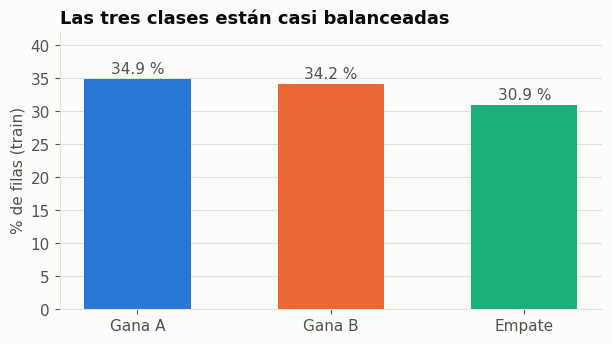

log loss de predecir siempre la proporción de cada clase: 1.0972
log loss de predecir 1/3 para todo:                       1.0986
A gana entre las decisiones sin empate: 50.5 %


In [2]:
counts = df["label"].value_counts(normalize=True).sort_index() * 100
names = ["Gana A", "Gana B", "Empate"]

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(names, counts.values, color=[BLUE, ORANGE, AQUA], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f} %", ha="center", color=INK2)
ax.set_ylim(0, 42)
ax.set_ylabel("% de filas (train)")
ax.set_title("Las tres clases están casi balanceadas")
plt.show()

p = counts.values / 100
decisive = df[df["label"] != 2]
print(f"log loss de predecir siempre la proporción de cada clase: {-(p * np.log(p)).sum():.4f}")
print(f"log loss de predecir 1/3 para todo:                       {np.log(3):.4f}")
print(f"A gana entre las decisiones sin empate: {(decisive['label'] == 0).mean() * 100:.1f} %")

## 2. Longitud del texto

Un modelo de lenguaje recibe prompt + las dos respuestas. Los tokens se estiman como
caracteres / 4 (aproximación común para inglés; el conteo real depende del tokenizador).
El 90 % de las filas cabe en ~1.5K tokens y el 99 % en ~3.8K; hay una cola larga.

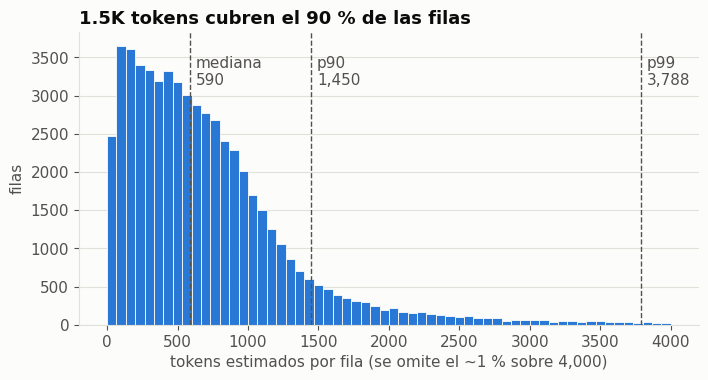

prompt: mediana 91 caracteres
respuesta A / B: mediana 1036 / 1044 caracteres
conversaciones con más de un turno: 13.1 %
respuestas vacías (A o B): 44


In [3]:
total_chars = df["prompt"].str.len() + df["len_a"] + df["len_b"]
tokens = total_chars / 4
q50, q90, q99 = tokens.quantile([0.5, 0.9, 0.99])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(tokens, bins=60, range=(0, 4000), color=BLUE, edgecolor=SURFACE, linewidth=0.6)
for q, label in [(q50, "mediana"), (q90, "p90"), (q99, "p99")]:
    ax.axvline(q, color=INK2, lw=1, ls="--")
    ax.text(q + 40, ax.get_ylim()[1] * 0.92, f"{label}\n{q:,.0f}", color=INK2, va="top")
ax.set_xlabel("tokens estimados por fila (se omite el ~1 % sobre 4,000)")
ax.set_ylabel("filas")
ax.set_title("1.5K tokens cubren el 90 % de las filas")
plt.show()

print("prompt: mediana", int(df["prompt"].str.len().median()), "caracteres")
print("respuesta A / B: mediana", int(df["len_a"].median()), "/", int(df["len_b"].median()), "caracteres")
print("conversaciones con más de un turno:", f"{(df['prompt_turns'].map(len) > 1).mean() * 100:.1f} %")
print("respuestas vacías (A o B):", int(((df['len_a'] == 0) | (df['len_b'] == 0)).sum()))

## 3. Sesgo de verbosidad

La señal más fuerte hasta ahora: **la respuesta más larga gana más veces**. Cuando A es
mucho más larga que B, A gana ~50 % y B ~23 %; cuando B es mucho más larga, pasa al revés.
Entre las decisiones sin empate y con longitudes distintas, la más larga gana el 61.6 %.

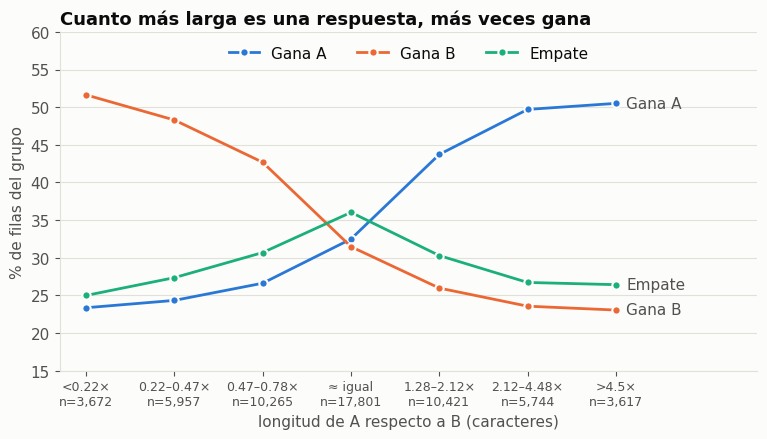

la respuesta más larga gana (sin empates, longitudes distintas): 61.6 % de 39,611


In [4]:
edges = [-10, -1.5, -0.75, -0.25, 0.25, 0.75, 1.5, 10]
ratio_edges = np.exp(edges[1:-1])
labels = [f"<{ratio_edges[0]:.2f}×"]
labels += [f"{lo:.2f}–{hi:.2f}×" for lo, hi in zip(ratio_edges[:-1], ratio_edges[1:])]
labels += [f">{ratio_edges[-1]:.1f}×"]
labels[3] = "≈ igual"

df["len_bin"] = pd.cut(df["log_ratio"], edges, labels=labels)
rates = df.groupby("len_bin", observed=True)["label"].value_counts(normalize=True).unstack() * 100
n_bin = df.groupby("len_bin", observed=True).size()

fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(rates))
for col, color, name in [(0, BLUE, "Gana A"), (1, ORANGE, "Gana B"), (2, AQUA, "Empate")]:
    ax.plot(x, rates[col], color=color, lw=2, marker="o", ms=6, mfc=color, mec=SURFACE, mew=1.5, label=name)
    ax.text(x[-1] + 0.12, rates[col].iloc[-1], name, color=INK2, va="center")
ax.set_xticks(x)
ax.set_xticklabels([f"{l}\nn={n:,}" for l, n in zip(rates.index, n_bin)], fontsize=9)
ax.set_xlim(-0.3, len(x) - 0.3 + 0.9)
ax.set_xlabel("longitud de A respecto a B (caracteres)")
ax.set_ylabel("% de filas del grupo")
ax.set_ylim(15, 60)
ax.set_title("Cuanto más larga es una respuesta, más veces gana")
ax.legend(loc="upper center", ncol=3)
plt.show()

nonzero = decisive[decisive["len_a"] != decisive["len_b"]]
longer_wins = ((nonzero["len_a"] > nonzero["len_b"]) == (nonzero["label"] == 0)).mean()
print(f"la respuesta más larga gana (sin empates, longitudes distintas): {longer_wins * 100:.1f} % de {len(nonzero):,}")

## 4. Empates

Los empates son el 31 % de las filas y son la clase más difícil. Dos pistas:

- Si las dos respuestas son **idénticas**, el 90 % termina en empate (275 filas).
- Cuanto **más parecidas en longitud**, más empates: casi 40 % cuando la diferencia es
  mínima y ~26 % cuando una respuesta es mucho más larga.

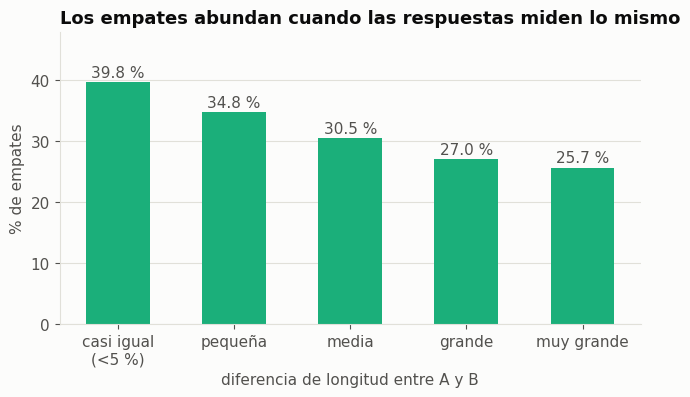

respuestas idénticas: 275 filas, 90.2 % son empate


In [5]:
abs_edges = [-1, 0.05, 0.25, 0.75, 1.5, 10]
abs_labels = ["casi igual\n(<5 %)", "pequeña", "media", "grande", "muy grande"]
tie_by_gap = (df.groupby(pd.cut(df["log_ratio"].abs(), abs_edges, labels=abs_labels), observed=True)["label"]
                .apply(lambda s: (s == 2).mean() * 100))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.bar(tie_by_gap.index.astype(str), tie_by_gap.values, color=AQUA, width=0.55)
for b, v in zip(bars, tie_by_gap.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.8, f"{v:.1f} %", ha="center", color=INK2)
ax.set_ylim(0, 48)
ax.set_xlabel("diferencia de longitud entre A y B")
ax.set_ylabel("% de empates")
ax.set_title("Los empates abundan cuando las respuestas miden lo mismo")
plt.show()

same = df[df["response_a"] == df["response_b"]]
print(f"respuestas idénticas: {len(same)} filas, {(same['label'] == 2).mean() * 100:.1f} % son empate")

## 5. Modelos ganadores (solo descriptivo)

`model_a` y `model_b` existen únicamente en train, así que **no pueden ser features**.
Sirven para entender qué estilo prefieren los usuarios: los GPT-4 y
`gpt-3.5-turbo-0314` encabezan la tabla, mientras que los modelos pequeños (3B a 12B, como
`chatglm`, `dolly` y `fastchat`) cierran con menos de la mitad del promedio.

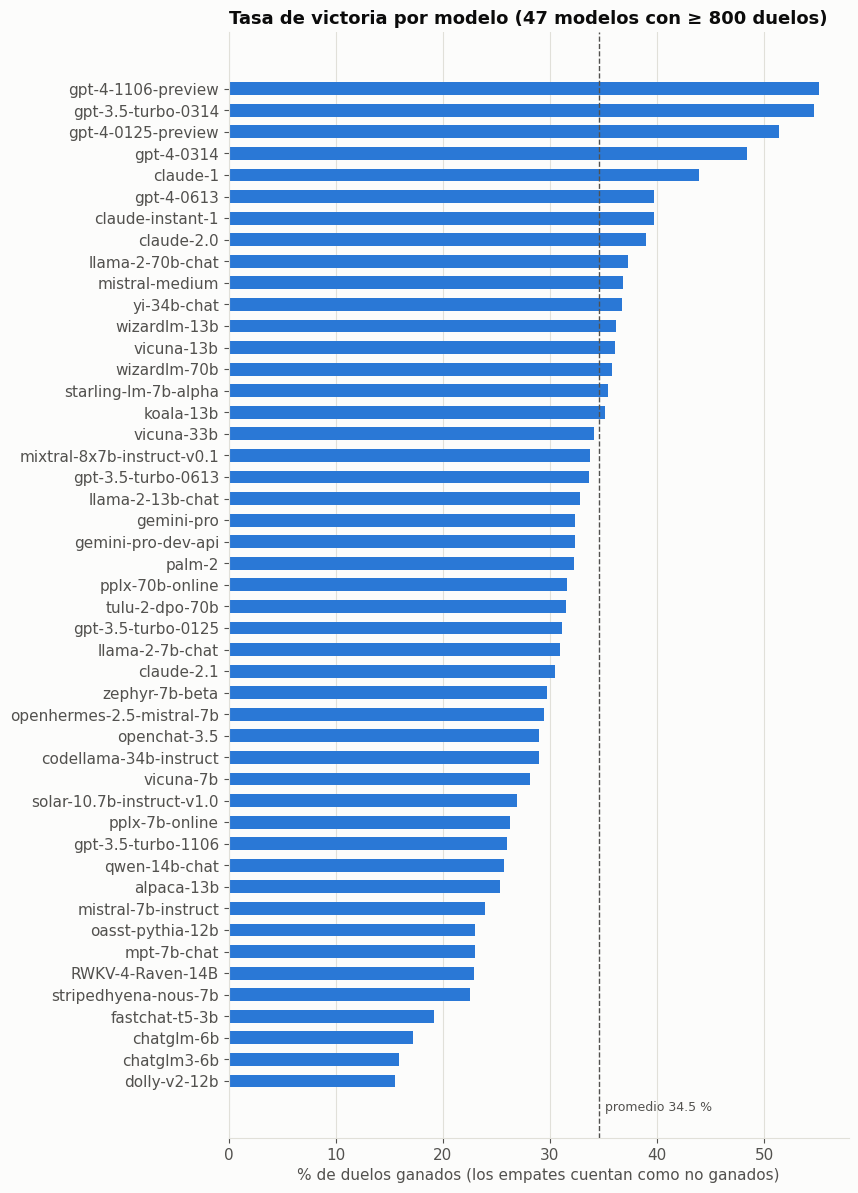

In [6]:
long_models = pd.concat([
    df[["model_a", "label"]].rename(columns={"model_a": "model"}).assign(win=lambda d: d["label"] == 0),
    df[["model_b", "label"]].rename(columns={"model_b": "model"}).assign(win=lambda d: d["label"] == 1),
])
by_model = (long_models.groupby("model")["win"].agg(["mean", "size"])
            .query("size >= 800").sort_values("mean"))
overall = long_models["win"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 0.28 * len(by_model) + 1.2))
ax.barh(by_model.index, by_model["mean"] * 100, color=BLUE, height=0.6)
ax.axvline(overall, color=INK2, lw=1, ls="--")
ax.text(overall + 0.6, -0.9, f"promedio {overall:.1f} %", color=INK2, fontsize=9, va="top")
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_xlabel("% de duelos ganados (los empates cuentan como no ganados)")
ax.set_title(f"Tasa de victoria por modelo ({len(by_model)} modelos con ≥ 800 duelos)")
plt.show()

## 6. Prompts repetidos

Hay 51,734 prompts distintos en 57,477 filas, y 8,861 filas pertenecen a un prompt que
aparece más de una vez (muchos son pruebas como `test` o "Write a single dot"). En esas
filas los empates suben a ~40 %, así que no se comportan como el resto.

Si una misma pregunta cae en train y en validación, la validación se infla.
En la Fase 2 la validación cruzada debe **agrupar por `prompt`** (`GroupKFold`).

In [7]:
vc = df["prompt"].value_counts()
df["prompt_count"] = df["prompt"].map(vc)
rep = df["prompt_count"] > 1

print(f"prompts distintos: {len(vc):,} de {len(df):,} filas")
print(f"filas con prompt repetido: {rep.sum():,} ({rep.mean() * 100:.1f} %)")
summary = pd.DataFrame({
    "filas": [int((~rep).sum()), int(rep.sum())],
    "gana A %": [(df.loc[~rep, "label"] == 0).mean() * 100, (df.loc[rep, "label"] == 0).mean() * 100],
    "gana B %": [(df.loc[~rep, "label"] == 1).mean() * 100, (df.loc[rep, "label"] == 1).mean() * 100],
    "empate %": [(df.loc[~rep, "label"] == 2).mean() * 100, (df.loc[rep, "label"] == 2).mean() * 100],
}, index=["prompt único", "prompt repetido"]).round(1)
summary

prompts distintos: 51,734 de 57,477 filas
filas con prompt repetido: 8,861 (15.4 %)


,filas,gana A %,gana B %,empate %
prompt único,48616,35.7,35.1,29.2
prompt repetido,8861,30.3,29.2,40.5


## 7. Señales de estructura

Qué tan relacionado está cada rasgo con la preferencia. Para cada fila se calcula el rasgo
de A menos el de B, y se correlaciona con +1 (gana A) o −1 (gana B), solo en decisiones sin
empate. Es un primer filtro para la Fase 2, no un modelo.
Azul favorece a A y naranja favorece a B.

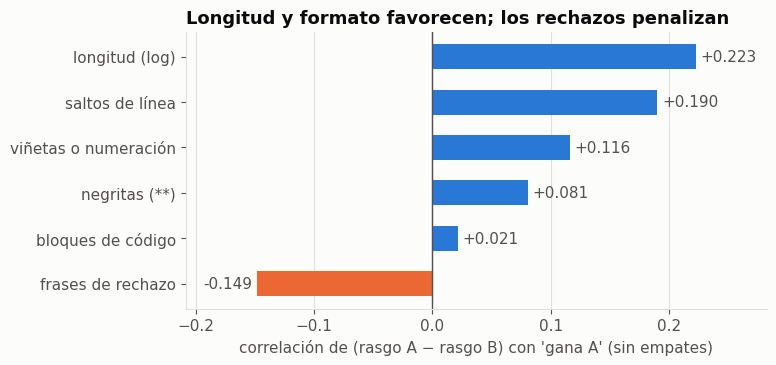

frases de rechazo      -0.149
bloques de código       0.021
negritas (**)           0.081
viñetas o numeración    0.116
saltos de línea         0.190
longitud (log)          0.223
dtype: float64

In [8]:
FEATURES = {
    "longitud (log)":        lambda s: np.log1p(s.str.len()),
    "saltos de línea":       lambda s: s.str.count("\n"),
    "viñetas o numeración":  lambda s: s.str.count(r"(?m)^\s*(?:[-*•]|\d+[.)])\s"),
    "negritas (**)":         lambda s: s.str.count(r"\*\*") / 2,
    "bloques de código":     lambda s: s.str.count("```") / 2,
    "frases de rechazo":     lambda s: s.str.contains(
        r"(?i)as an ai|i cannot|i can't|i'm sorry|i am sorry|i apologize").astype(int),
}
dec = df[df["label"] != 2].copy()
signed = np.where(dec["label"] == 0, 1, -1)

corr = pd.Series({
    name: np.corrcoef(f(dec["response_a"]) - f(dec["response_b"]), signed)[0, 1]
    for name, f in FEATURES.items()
}).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(corr.index, corr.values, color=[BLUE if v >= 0 else ORANGE for v in corr.values], height=0.55)
for y, v in enumerate(corr.values):
    ax.text(v + (0.004 if v >= 0 else -0.004), y, f"{v:+.3f}", va="center",
            ha="left" if v >= 0 else "right", color=INK2)
ax.axvline(0, color=INK2, lw=1)
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_xlim(min(corr.min() - 0.06, -0.08), corr.max() + 0.06)
ax.set_xlabel("correlación de (rasgo A − rasgo B) con 'gana A' (sin empates)")
ax.set_title("Longitud y formato favorecen; los rechazos penalizan")
plt.show()
corr.round(3)

## Conclusiones para la Fase 2

1. **Baseline de referencia:** log loss ≈ 1.0986 con probabilidades uniformes (≈ 1.0972 con
   las proporciones de clase). Cualquier modelo debe bajar de ahí.
2. **Features de diferencia:** longitud, saltos de línea, viñetas y negritas de A menos B,
   más sus razones. La longitud es la señal más fuerte (+0.22), seguida de saltos de línea
   (+0.19) y viñetas (+0.12). Las frases de rechazo ("I cannot", "as an AI") penalizan (−0.15).
   Los bloques de código casi no aportan solos (+0.02).
3. **Simetría A/B:** casi no hay sesgo de posición, así que se puede duplicar el train
   intercambiando A y B (y sus etiquetas) sin distorsionar los datos.
4. **Empates:** son la clase difícil; hay que dar al modelo la similitud entre respuestas
   (diferencia de longitud, igualdad exacta) para que pueda predecirlos.
5. **Validación:** `GroupKFold` por `prompt` para evitar fuga entre folds.
6. **Contexto para el LLM (Fase 5):** ~1.5K tokens cubren el 90 % de las filas y ~3.8K el 99 %.
7. **`model_a` / `model_b`:** solo descriptivos, no entran al modelo.